In [2]:
%load_ext autoreload
%autoreload 1
%aimport PileUp_analysis.utility.functions
%aimport PileUp_analysis.src.analysis
%aimport PileUp_analysis.src.dataset
%aimport PileUp_analysis.src.high_analysis
import numpy as np
import PileUp_analysis.utility.functions as fn
import PileUp_analysis.src.analysis as an
import PileUp_analysis.src.dataset as ds
import PileUp_analysis.src.high_analysis as ha
import matplotlib.pyplot as plt

In [2]:
for channel in [3,5,9,11,13,15,17,19]:
    mean, bslspec = ds.get_meanpulse_ANPS(channel)
    data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = ds.create_data_sets(channel,-1,pos_prefix="_bis")
    transf_OF,_ = an.compute_transfer_simple(mean, bslspec)
    
    best_params,_= ds.get_best_param(channel)
    mg = fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_PU,_ = an.compute_transfer_simple(mean,mg*bslspec )
    
    filtered_amp_single, argmax_single = an.get_interpolate_filtered_amp(data_single, transf_PU, arg_max=1999)
    fitted_amp_single = an.get_interpolate_fitted_amp(data_single, transf_PU, argmax_single, mean,jitter = 150)
    chi2_single = an.get_interpolate_chi2(data_single, transf_PU, argmax_single, mean)
    
    filtered_amp_pileup, argmax_pileup = an.get_interpolate_filtered_amp(data_pileup, transf_PU, arg_max=1999)
    fitted_amp_pileup = an.get_interpolate_fitted_amp(data_pileup, transf_PU, argmax_pileup, mean,jitter = 150)
    chi2_pileup = an.get_interpolate_chi2(data_pileup, transf_PU, argmax_pileup, mean)
    PSD_single = filtered_amp_single[:,0]/fitted_amp_single
    PSD_pileup = filtered_amp_pileup[:,0]/fitted_amp_pileup
    cut = np.percentile(PSD_single,10)
    rp = np.sum(PSD_pileup<cut)/len(PSD_pileup)
    print(channel,rp,fn.calculate_BI(rp,0.8)*1e5)

3 0.7614666666666666 6.291834051082423
5 0.7882 5.586684399186376
9 0.6255333333333334 9.877370560349346
11 0.7594 6.346346867064411
13 0.8572666666666666 3.764901258627018
15 0.7029333333333333 7.83577767792713
17 0.8891333333333333 2.9243488057434512
19 0.759 6.356897734673826


In [4]:
for channel in [3,5,9,11,13,15,17,19]:
    mean, bslspec = ds.get_meanpulse_ANPS(channel)
    data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = ds.create_data_sets(channel,-2,pos_prefix="_bis")
    # transf_OF,_ = an.compute_transfer_simple(mean, bslspec)
    
    best_params,_= ds.get_best_param(channel)
    mg = fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_PU,_ = an.compute_transfer_simple(mean,mg*bslspec )
    
    filtered_amp_single, argmax_single = an.get_interpolate_filtered_amp(data_single, transf_PU, arg_max=1999,subsample_size = 1)
    fitted_amp_single = an.get_interpolate_fitted_amp(data_single, transf_PU, argmax_single, mean,jitter = 150)
    # chi2_single = an.get_interpolate_chi2(data_single, transf_PU, argmax_single, mean)
    
    filtered_amp_pileup, argmax_pileup = an.get_interpolate_filtered_amp(data_pileup, transf_PU, arg_max=1999,subsample_size = 1)
    fitted_amp_pileup = an.get_interpolate_fitted_amp(data_pileup, transf_PU, argmax_pileup, mean,jitter = 150)
    # chi2_pileup = an.get_interpolate_chi2(data_pileup, transf_PU, argmax_pileup, mean)
    PSD_single = filtered_amp_single[:,0]/fitted_amp_single
    PSD_pileup = filtered_amp_pileup[:,0]/fitted_amp_pileup
    cut = np.percentile(PSD_single,10)
    rp = np.sum(PSD_pileup<cut)/len(PSD_pileup)
    print(channel,rp,fn.calculate_BI(rp,0.8)*1e5)


3 0.7796666666666666 5.811769574853942
5 0.7782666666666667 5.8486976114869025
9 0.9980666666666667 0.05099586011218309
11 0.8006 5.259607503294446
13 0.7878666666666667 5.59547678886089
15 0.7117333333333333 7.603658590519955
17 0.9522666666666667 1.2590702013904447
19 0.9079333333333334 2.4284580281008443


In [48]:
for channel in [3,5,9,11,13,15,17,19]:
    mean, bslspec = ds.get_meanpulse_ANPS(channel)
    data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = ds.create_data_sets(channel,-1,pos_prefix="_bis")
    transf_OF,_ = an.compute_transfer_simple(mean, bslspec)
    # 
    best_params,_= ds.get_best_param(channel)
    mg = fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_PU,_ = an.compute_transfer_simple(mean,mg*bslspec )
    filtered_amp_single_OF, argmax_single_OF = an.get_interpolate_filtered_amp(data_single, transf_OF, arg_max=1999,subsample_size = 0.01,jitter_max = 3)
    filtered_amp_single, argmax_single = an.get_interpolate_filtered_amp(data_single, transf_PU, arg_max=1999,pos_max_inter=argmax_single_OF,subsample_size = 0.01,jitter_max = 3)
    fitted_amp_single = an.get_interpolate_fitted_amp(data_single, transf_PU, argmax_single_OF, mean,jitter = 150)
    # chi2_single = an.get_interpolate_chi2(data_single, transf_PU, argmax_single, mean)
    filtered_amp_pileup_OF, argmax_pileup_OF = an.get_interpolate_filtered_amp(data_pileup, transf_OF, arg_max=1999,subsample_size = 0.01,jitter_max = 3)
    filtered_amp_pileup, argmax_pileup = an.get_interpolate_filtered_amp(data_pileup, transf_PU, arg_max=1999,pos_max_inter=argmax_pileup_OF,subsample_size = 0.01,jitter_max = 3)
    fitted_amp_pileup = an.get_interpolate_fitted_amp(data_pileup, transf_PU, argmax_pileup_OF, mean,jitter = 150)
    # chi2_pileup = an.get_interpolate_chi2(data_pileup, transf_PU, argmax_pileup, mean)
    PSD_single = filtered_amp_single/fitted_amp_single
    PSD_pileup = filtered_amp_pileup/fitted_amp_pileup
    cut = np.percentile(PSD_single,10)
    rp = np.sum(PSD_pileup<cut)/len(PSD_pileup)
    print(channel,rp,fn.calculate_BI(rp,0.8)*1e5)

3 0.7966 5.365116179388617
5 0.7713333333333333 6.031579316716798
9 0.7403333333333333 6.849271556446627
11 0.7446666666666667 6.734970490677942
13 0.7843333333333333 5.688676119410742
15 0.692 8.1241680592512
17 0.7556666666666667 6.44482163141897
19 0.6867333333333333 8.263087816108525


In [495]:
from scipy.interpolate import interp1d
def get_everything(data_single,data_pileup,mean, bslspec):
    best_params,_= ds.get_best_param(channel)
    mg = fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_OF,_ = an.compute_transfer_simple(mean,bslspec)
    transf_PU,_ = an.compute_transfer_simple(mean,bslspec*mg)
    filtered_amp_single, argmax_single = an.get_interpolate_filtered_amp(data_single, transf_PU, arg_max=1999,subsample_size = 0.01,jitter_max = 3)
    # filtered_amp_single, argmax_single = an.get_interpolate_filtered_amp(data_single, transf_OF, arg_max=1999,pos_max_inter=argmax_single_OF,subsample_size = 0.01,jitter_max = 3)
    fitted_amp_single = an.get_interpolate_fitted_amp_bis(data_single, transf_PU, argmax_single, mean,jitter = 150)
    chi2_single = an.get_interpolate_chi2_stat(data_single, transf_PU, argmax_single, mean)
    
    filtered_amp_pileup, argmax_pileup = an.get_interpolate_filtered_amp(data_pileup, transf_PU, arg_max=1999,subsample_size = 0.01,jitter_max = 3)
    # filtered_amp_pileup, argmax_pileup = an.get_interpolate_filtered_amp(data_pileup, transf_OF, arg_max=1999,pos_max_inter=argmax_pileup_OF,subsample_size = 0.01,jitter_max = 3)
    fitted_amp_pileup = an.get_interpolate_fitted_amp_bis(data_pileup, transf_PU, argmax_pileup, mean,jitter = 150)
    chi2_pileup = an.get_interpolate_chi2_stat(data_pileup, transf_PU, argmax_pileup, mean)
    return filtered_amp_single,fitted_amp_single,chi2_single,argmax_single,filtered_amp_pileup,fitted_amp_pileup,chi2_pileup,argmax_pileup

def get_centered_meanpulse(meanpulse,pos_max = 999):
    y = np.pad(meanpulse,(100,100),mode="constant",constant_values=(0,0))
    x = np.arange(len(y))
    interp_func = interp1d(x, y, kind='cubic', bounds_error=False, fill_value='extrapolate')
    x_inter = np.arange(0,len(y),0.01)
    y_inter = interp_func(x_inter)
    return y_inter[np.argmax(y_inter)-pos_max*100:np.argmax(y_inter)+len(meanpulse)*100-pos_max*100:100]
    
    

In [557]:
for channel in [3,5,9,11,13,15,17,19]:
    
    meanpulse, bslspec = ds.get_meanpulse_ANPS(channel)
    data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = ds.create_data_sets(channel,-1,pos_prefix="_bis")
    best_params,_= ds.get_best_param(channel)
    mg = fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_OF,_ = an.compute_transfer_simple(meanpulse,bslspec)
    transf_PU,_ = an.compute_transfer_simple(meanpulse,bslspec*mg)
    PSD_single,filtered_amp_single,_,_ = an.get_PSD(data_single, transf_PU, meanpulse,transferfunc_max=transf_OF)
    PSD_pileup,filtered_amp_pileup,_,_ = an.get_PSD(data_pileup, transf_PU, meanpulse,transferfunc_max=transf_OF)
    cut = np.percentile(PSD_single,10)
    rp = np.sum(PSD_pileup<cut)/len(PSD_pileup)
    print(channel,np.sum(PSD_single>cut)/len(PSD_single),rp,fn.calculate_BI(rp,0.8)*1e5)
    

{'A': 36.598234443677974, 'f0': 180.0, 'sigma': 0.7000000000000002}
3 0.9 0.7979333333333334 5.329946620690556
{'A': 16.444646771097048, 'f0': 160.0, 'sigma': 0.7000000000000002}
5 0.9 0.7708666666666667 6.043888662261119
{'A': 44.701184493300794, 'f0': 240.0, 'sigma': 0.6000000000000001}
9 0.9 0.7612666666666666 6.297109484887131
{'A': 44.701184493300794, 'f0': 180.0, 'sigma': 0.8000000000000003}
11 0.9 0.7796666666666666 5.811769574853942
{'A': 81.45086866496807, 'f0': 240.0, 'sigma': 0.6000000000000001}
13 0.9 0.8019333333333334 5.224437944596386
{'A': 29.964100047396997, 'f0': 200.0, 'sigma': 0.6000000000000001}
15 0.9 0.7186 7.422535363224957
{'A': 16.444646771097048, 'f0': 180.0, 'sigma': 0.6000000000000001}
17 0.9 0.783 5.723845678108798
{'A': 16.444646771097048, 'f0': 260.0, 'sigma': 0.6000000000000001}
19 0.9 0.7163333333333334 7.482323613011654


In [617]:
for channel in [3]:
    meanpulse, bslspec = ds.get_meanpulse_ANPS(channel)
    data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = ds.create_data_sets(channel,-1,pos_prefix="_bis")
    best_params,_= ds.get_best_param(channel)
    mg = fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_OF,_ = an.compute_transfer_simple(meanpulse,bslspec)
    transf_PU,_ = an.compute_transfer_simple(meanpulse,bslspec/fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),10,np.log(1000),0.4,1))
    print(transf_PU.shape)
    PSD_single,filtered_amp_single,_,_ = an.get_PSD(data_single, transf_PU, meanpulse,transferfunc_max=transf_OF)
    PSD_pileup,filtered_amp_pileup,_,_ = an.get_PSD(data_pileup, transf_PU, meanpulse,transferfunc_max=transf_OF)
    cut = np.percentile(PSD_single,10)
    rp = np.sum(PSD_pileup<cut)/len(PSD_pileup)
    print(channel,np.sum(PSD_single>cut)/len(PSD_single),rp,fn.calculate_BI(rp,0.8)*1e5)
    # PSD_single,filtered_amp_single,_,_ = an.get_PSD(data_single, transf_OF, meanpulse,transferfunc_max=transf_OF)
    # PSD_pileup,filtered_amp_pileup,_,_ = an.get_PSD(data_pileup, transf_OF, meanpulse,transferfunc_max=transf_OF)
    # cut = np.percentile(PSD_single,10)
    # rp = np.sum(PSD_pileup<cut)/len(PSD_pileup)
    # print(channel,np.sum(PSD_single>cut)/len(PSD_single),rp,fn.calculate_BI(rp,0.8)*1e5)

(4000,)
3 0.9 0.7847333333333333 5.678125251801326


In [614]:
3 0.9 0.7848 5.6763667738664205

([2.0,
  2.4809436693226274,
  3.0775407451760115,
  3.8176026144134334,
  4.735628519109259,
  5.874413797373904,
  7.287044860788141,
  9.039373907721162,
  11.213088735500481,
  13.90952075594639,
  17.254368731388446,
  21.403558436148227,
  26.550511401569427,
  32.935161589500964,
  40.85514032179508,
  50.679650870322575,
  62.86667949510388,
  77.98434525235626,
  96.73738383005171,
  119.99999999999997],)

3 0.9 0.7966 5.365116179388617
3 0.2258 0.9045333333333333 2.518140402780892
3 0.9120666666666667 0.789 5.565582663967541


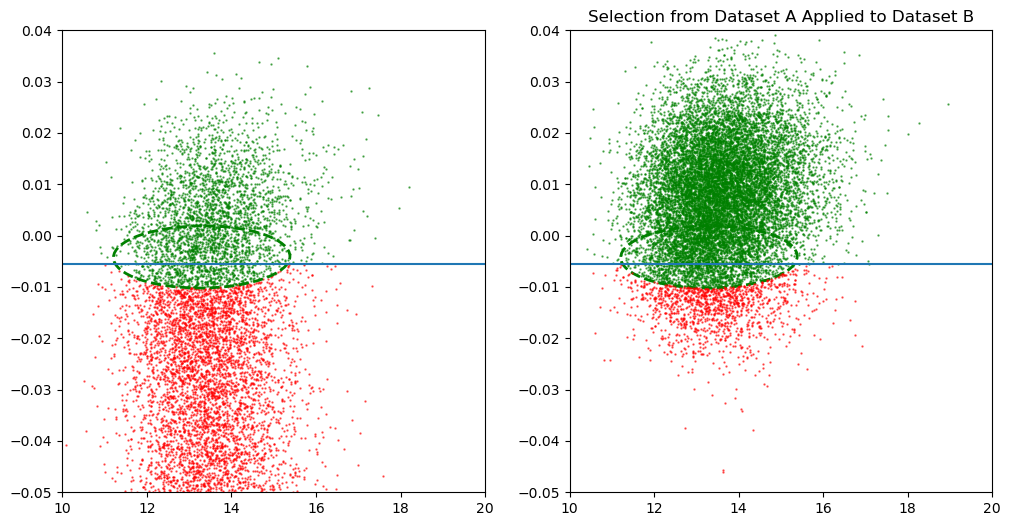

In [245]:
from matplotlib.colors import LogNorm
xA =  chi2_single#(argmax_single_OF/argmax_single -1)*100
yA = filtered_amp_single/fitted_amp_single-1
xB =  chi2_pileup#(argmax_pileup_OF/argmax_pileup-1)*100
yB =  filtered_amp_pileup/fitted_amp_pileup-1
cut = np.percentile(yA,10)
rp = np.sum(yB<cut)/len(yB)
print(channel,np.sum(yA>cut)/len(yA),rp,fn.calculate_BI(rp,0.8)*1e5)
cut = np.percentile(yA,15)
sel= (yA<0.00)&(yA>-0.01)&(xA<20)&(xA>10)
dataA = np.column_stack((xA[sel], yA[sel]))
# Compute ellipse parameters from dataset A
mean_A = np.median(dataA, axis=0)
cov_A = np.cov(dataA, rowvar=False)
confidence = 0.9
mask_A = ha.get_mask(xA, yA, mean_A, cov_A, confidence=confidence)
# Get inliers/outliers in B based on ellipse from A
mask_B = ha.get_mask(xB, yB, mean_A, cov_A, confidence=confidence)
# print(channel, np.sum(mask_A)/len(xA),1-np.sum(mask_B)/len(xB),fn.calculate_BI(1-np.sum(mask_B)/len(xB),0.8)*1e5)
mask_A_b = mask_A|(yA>cut)
mask_B_b = mask_B|(yB>cut)
print(channel, np.sum(mask_A)/len(xA),1-np.sum(mask_B)/len(xB),fn.calculate_BI(1-np.sum(mask_B)/len(xB),0.8)*1e5)
print(channel, np.sum(mask_A_b)/len(xA),1-np.sum(mask_B_b)/len(xB),fn.calculate_BI(1-np.sum(mask_B_b)/len(xB),0.8)*1e5)
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(12,6))
# # ax.scatter(xA, yA, s=0.5, c='blue', label='All A', alpha=0.6)
ax1.scatter(xB[mask_B_b], yB[mask_B_b], s=0.5, c='green', label='Inliers in B', alpha=0.6)
ax1.scatter(xB[~mask_B_b], yB[~mask_B_b], s=0.5, c='red', label='Outliers in B', alpha=0.6)
# ax.hist2d(xB, yB,np.arange(-0.1,0.04,0.0005) , label='All A', norm=LogNorm())
ha.draw_confidence_ellipse(mean_A, cov_A, confidence=confidence, ax=ax2, linestyle='--',edgecolor="g")
ax1.hlines(cut,0,70)
# ax.legend()
plt.title("Selection from Dataset A Applied to Dataset B")

ax1.set_ylim(-0.05,0.04)
ax1.set_xlim(10,20)

ax2.scatter(xA[mask_A_b], yA[mask_A_b], s=0.5, c='green', label='All A', alpha=0.6)
ax2.scatter(xA[~mask_A_b], yA[~mask_A_b], s=0.5, c='red', label='All A', alpha=0.6)
# ax.hist2d(xA, yA,np.arange(-0.1,0.04,0.0005) , label='All A', norm=LogNorm())
# ax.scatter(xB[mask_B_b], yB[mask_B_b], s=0.5, c='green', label='Inliers in B', alpha=0.6)
# ax.scatter(xB[~mask_B_b], yB[~mask_B_b], s=0.5, c='red', label='Outliers in B', alpha=0.6)
ha.draw_confidence_ellipse(mean_A, cov_A, confidence=confidence, ax=ax1, linestyle='--',edgecolor="g")
ax2.hlines(cut,0,70)
# ax.legend()
plt.title("Selection from Dataset A Applied to Dataset B")
plt.ylim(-0.05,0.04)
plt.xlim(10,20)
plt.show()



[ 647.5  650.   652.5  655.   657.5  660.   662.5  665.   667.5  670.
  672.5  675.   677.5  680.   682.5  685.   687.5  690.   692.5  695.
  697.5  700.   702.5  705.   707.5  710.   712.5  715.   717.5  720.
  722.5  725.   727.5  730.   732.5  735.   737.5  740.   742.5  745.
  747.5  750.   752.5  755.   757.5  760.   762.5  765.   767.5  770.
  772.5  775.   777.5  780.   782.5  785.   787.5  790.   792.5  795.
  797.5  800.   802.5  805.   807.5  810.   812.5  815.   817.5  820.
  822.5  825.   827.5  830.   832.5  835.   837.5  840.   842.5  845.
  847.5  850.   852.5  855.   857.5  860.   862.5  865.   867.5  870.
  872.5  875.   877.5  880.   882.5  885.   887.5  890.   892.5  895.
  897.5  900.   902.5  905.   907.5  910.   912.5  915.   917.5  920.
  922.5  925.   927.5  930.   932.5  935.   937.5  940.   942.5  945.
  947.5  950.   952.5  955.   957.5  960.   962.5  965.   967.5  970.
  972.5  975.   977.5  980.   982.5  985.   987.5  990.   992.5  995.
  997.5 1000.  1002.

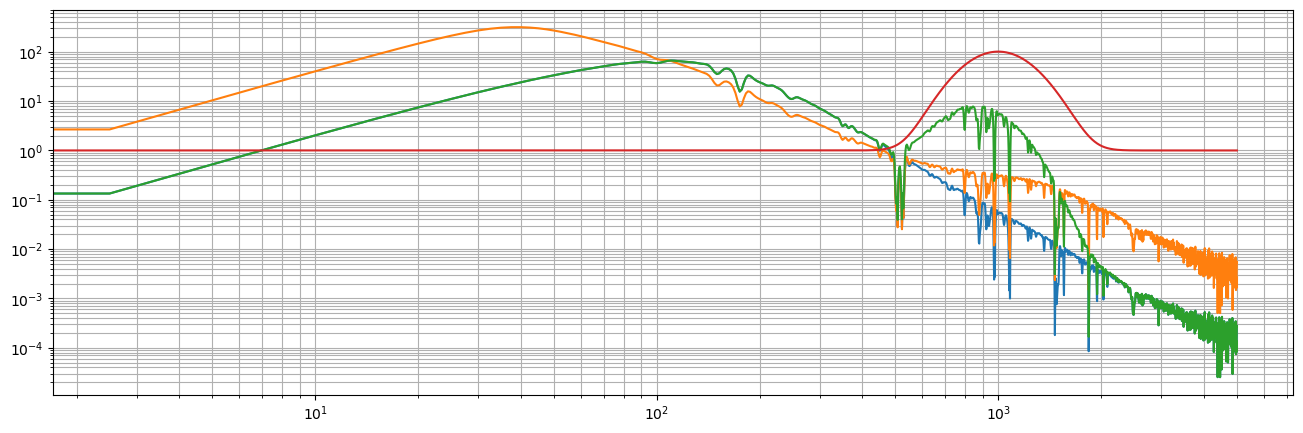

In [602]:
channel = 9
meanpulse, bslspec = ds.get_meanpulse_ANPS(channel)

best_params,_= ds.get_best_param(channel)
mg = fn.modified_gaussian(np.fft.fftfreq(2000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
transf_OF,_ = an.compute_transfer_simple(meanpulse,bslspec)
transf_PU,_ = an.compute_transfer_simple(meanpulse,bslspec*mg)
plt.figure(figsize = (16,5))
plt.plot(np.fft.fftfreq(4000,1e-4)[:2000],np.abs(transf_OF[:2000]))
plt.plot(np.fft.fftfreq(4000,1e-4)[:2000],np.abs(transf_PU[:2000]))
ft = fn.modified_gaussian(np.fft.fftfreq(4000,1e-4),100,np.log(1000),0.2,1)[:2000]
print(np.fft.fftfreq(4000,1e-4)[:2000][ft>ft.max()*0.1])
plt.plot(np.fft.fftfreq(4000,1e-4)[:2000],np.abs(transf_OF[:2000]*ft))
plt.plot(np.fft.fftfreq(4000,1e-4)[:2000],ft)
# plt.plot(np.fft.fftfreq(2000,1e-4)[:1000],np.abs(np.fft.fft(meanpulse)[:1000]))
# plt.plot(np.fft.fftfreq(2000,1e-4)[:1000],1/bslspec[:1000])
plt.xscale("log")
plt.yscale("log")
plt.grid(True,"both")